# Jour 3 — Accidents aériens

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1706/chapter/4347), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## 1. Import et nettoyage
Encodage latin1 pour les caractères accentués du fichier. Les décès inconnus ne sont pas remplacés par zéro : une absence n’est pas une absence de victimes. Les dates invalides restent signalées et sont exclues des seules analyses temporelles.

In [2]:
from scipy import stats
df=pd.read_csv(course_file("Datasets-DA-Bootcamp-2-","W4 Gen AI/W4D3/Airplane Crashes and Fatalities upto 2023.zip","Airplane_Crashes_and_Fatalities_Since_1908_t0_2023.csv"),encoding="latin1")
print("Dimensions initiales",df.shape,"doublons",df.duplicated().sum())
df=df.drop_duplicates().copy();df["Date"]=pd.to_datetime(df["Date"],errors="coerce")
for c in ["Aboard","Fatalities","Ground"]:df[c]=pd.to_numeric(df[c],errors="coerce")
valid=(df["Aboard"]>0)&(df["Fatalities"]>=0)&(df["Fatalities"]<=df["Aboard"])
df["SurvivalRate"]=np.where(valid,(df["Aboard"]-df["Fatalities"])/df["Aboard"],np.nan)
df["Year"]=df["Date"].dt.year;df["Decade"]=(df["Year"]//10)*10
display(df.isna().sum().to_frame("manquants"));display(df.head())
print("Ratios exploitables",valid.sum(),"dates invalides",df["Date"].isna().sum())

Dimensions initiales (4998, 17) doublons 0


,manquants
Date,0
Time,1512
Location,4
Operator,10
Flight #,3669
Route,777
AC Type,15
Registration,274
cn/ln,668
Aboard,18


,Date,Time,Location,Operator,Flight #,Route,AC Type,Registration,cn/ln,Aboard,Aboard Passangers,Aboard Crew,Fatalities,Fatalities Passangers,Fatalities Crew,Ground,Summary,SurvivalRate,Year,Decade
0,1908-09-17,17:18,"Fort Myer, Virginia",Military - U.S. Army,NaN,Demonstration,Wright Flyer III,NaN,1,2.0,1.0,1.0,1.0,1.0,0.0,0.0,"During a demonstration flight, a U.S. Army fly...",0.5,1908,1900
1,1909-09-07,NaN,"Juvisy-sur-Orge, France",NaN,NaN,Air show,Wright Byplane,SC1,NaN,1.0,0.0,1.0,1.0,0.0,0.0,0.0,Eugene Lefebvre was the first pilot to ever be...,0.0,1909,1900
2,1912-07-12,6:30,"Atlantic City, New Jersey",Military - U.S. Navy,NaN,Test flight,Dirigible,NaN,NaN,5.0,0.0,5.0,5.0,0.0,5.0,0.0,First U.S. dirigible Akron exploded just offsh...,0.0,1912,1910
3,1913-08-06,NaN,"Victoria, British Columbia, Canada",Private,NaN,NaN,Curtiss seaplane,NaN,NaN,1.0,0.0,1.0,1.0,0.0,1.0,0.0,The first fatal airplane accident in Canada oc...,0.0,1913,1910
4,1913-09-09,18:30,Over the North Sea,Military - German Navy,NaN,NaN,Zeppelin L-1 (airship),NaN,NaN,20.0,NaN,NaN,14.0,NaN,NaN,0.0,The airship flew into a thunderstorm and encou...,0.3,1913,1910


Ratios exploitables 4975 dates invalides 0


## 2. Exploration
Le taux de survie concerne uniquement les personnes à bord et les événements documentés. Les victimes au sol sont comptées séparément. La moyenne des taux par accident et le taux pondéré par le nombre de personnes répondent à des questions différentes.

Accidents enregistrés 4998 décès à bord connus 111644.0 décès au sol connus 8520.0
Taux de survie pondéré 0.2819009243286387


,Fatalities,SurvivalRate
count,4990.000000,4975.000000
mean,22.373547,0.181489
std,35.061741,0.311724
min,0.000000,0.000000
25%,4.000000,0.000000
50%,11.000000,0.000000
75%,25.000000,0.250000
max,583.000000,1.000000


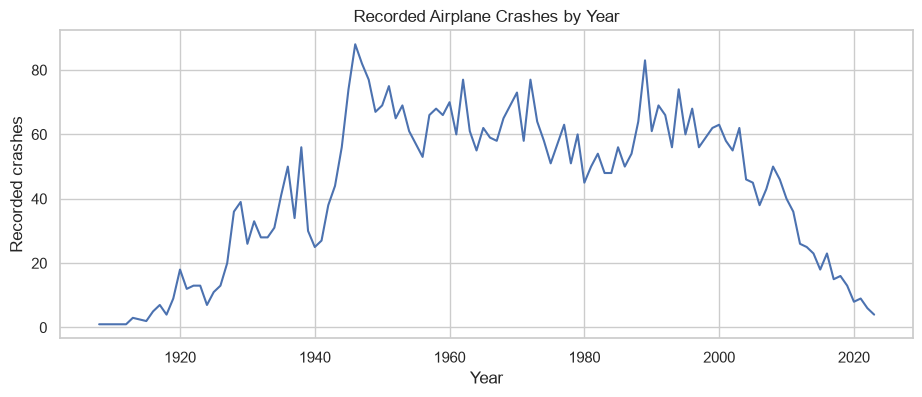

In [3]:
print("Accidents enregistrés",len(df),"décès à bord connus",df["Fatalities"].sum(min_count=1),"décès au sol connus",df["Ground"].sum(min_count=1))
print("Taux de survie pondéré",(df.loc[valid,"Aboard"].sum()-df.loc[valid,"Fatalities"].sum())/df.loc[valid,"Aboard"].sum())
display(df[["Fatalities","SurvivalRate"]].describe())
counts=df.groupby("Year").size()
counts.plot(figsize=(11,4));plt.xlabel("Year");plt.ylabel("Recorded crashes");plt.title("Recorded Airplane Crashes by Year");plt.show()

## 3. Statistiques SciPy et test
Comparaison planifiée entre les années 1980 et 1990 : H0 = mêmes nombres moyens de décès par accident ; Welch bilatéral, α=0,05. Les décès sont asymétriques, un bootstrap de la différence complète l’analyse. L’indépendance des événements et les différences de couverture historique limitent l’inférence.

In [4]:
for c in ["Fatalities","SurvivalRate"]:
    values=df[c].dropna().to_numpy();desc=stats.describe(values)
    print(c,"n",desc.nobs,"moyenne",desc.mean,"médiane",np.median(values),"écart-type échantillon",np.sqrt(desc.variance),"asymétrie",desc.skewness)
a=df.loc[df["Decade"].eq(1980),"Fatalities"].dropna().to_numpy()
b=df.loc[df["Decade"].eq(1990),"Fatalities"].dropna().to_numpy()
test=stats.ttest_ind(a,b,equal_var=False)
print("n 1980 / 1990",len(a),len(b),"moyennes",a.mean(),b.mean(),"t",test.statistic,"p",test.pvalue)
print("H0 rejetée" if test.pvalue<.05 else "H0 non rejetée")
rng=np.random.default_rng(42)
diffs=np.array([rng.choice(b,len(b),replace=True).mean()-rng.choice(a,len(a),replace=True).mean() for _ in range(3000)])
print("Différence 1990 - 1980",b.mean()-a.mean(),"IC bootstrap percentile 95 %",np.quantile(diffs,[.025,.975]))

Fatalities n 4990 moyenne 22.37354709418838 médiane 11.0 écart-type échantillon 35.061740659743165 asymétrie 4.606031652398515
SurvivalRate n 4975 moyenne 0.181489019431307 médiane 0.0 écart-type échantillon 0.3117242492487905 asymétrie 1.5460751516056843
n 1980 / 1990 552 631 moyennes 30.519927536231883 25.33122028526149 t 1.9450713304682148 p 0.052024888946359656
H0 non rejetée
Différence 1990 - 1980 -5.188707250970392 IC bootstrap percentile 95 % [-10.64386649   0.03515806]


## 4. Distributions et décennies

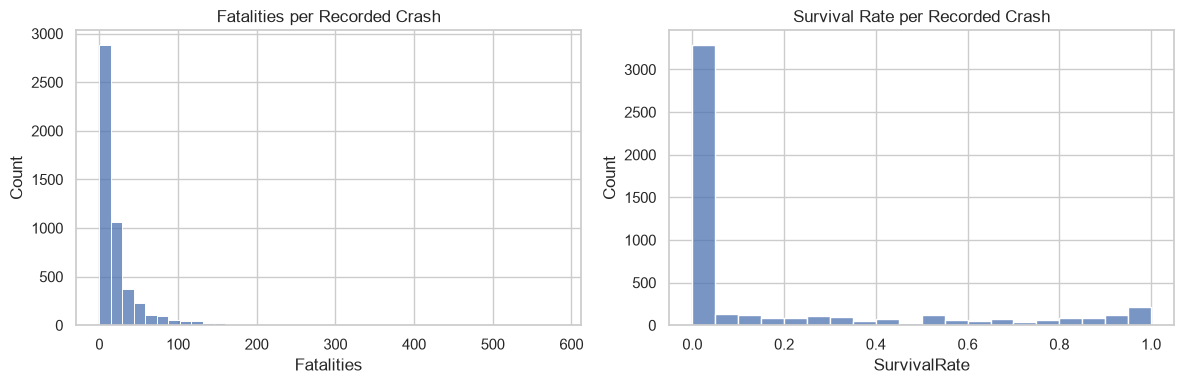

,count,sum,mean,median
Decade,,,,
1900,2,2.0,1.000000,1.0
1910,31,424.0,13.677419,18.0
1920,181,647.0,3.574586,2.0
1930,354,2033.0,5.742938,4.0
1940,575,8881.0,15.445217,14.0
1950,648,11779.0,18.177469,14.0
1960,636,16884.0,26.547170,19.0
1970,612,19751.0,32.272876,17.0
1980,552,16847.0,30.519928,14.0


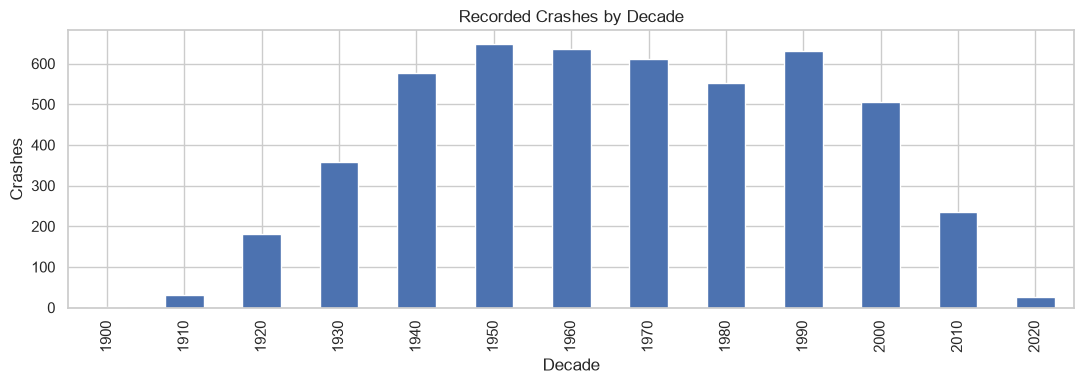

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=df,x="Fatalities",bins=40,ax=axes[0]);axes[0].set_title("Fatalities per Recorded Crash")
sns.histplot(data=df,x="SurvivalRate",bins=20,ax=axes[1]);axes[1].set_title("Survival Rate per Recorded Crash")
plt.tight_layout();plt.show()
decades=df.groupby("Decade")["Fatalities"].agg(["count","sum","mean","median"])
display(decades)
df.groupby("Decade").size().plot.bar(figsize=(11,4));plt.title("Recorded Crashes by Decade");plt.ylabel("Crashes");plt.tight_layout();plt.show()

## 5. Rapport et limites
Pandas sert au nettoyage et aux regroupements, NumPy aux ratios et au bootstrap, SciPy aux moments et au test. Les distributions de décès et de survie sont hétérogènes et le taux par événement ne doit pas être confondu avec le risque d’un vol. Il manque le nombre de vols, les kilomètres parcourus et un contrôle de la couverture : une baisse du nombre d’événements recensés ne suffit pas à quantifier une amélioration de sécurité. Les lieux sont du texte libre ; ils ne sont pas arbitrairement transformés en pays. Les tableaux et graphiques donnent les résultats observés sans extrapolation causale.